# Monthly Sales Forecasting

I wanted to try a classic time-series setup — trend + seasonality + noise — and forecast 12 months out. Rather than pull a competition CSV that may not be reachable, I'm generating ~60 months of synthetic monthly sales with a clear annual cycle and a mild upward trend. The reason for synthetic: I want to be honest about whether the model is *actually* recovering the pattern I put in, and that's only possible when I know the ground truth.

I'll fit a SARIMA baseline because Prophet is a bigger dependency and not everyone has it installed. If Prophet is available the same shape of forecast should work.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error

RNG = np.random.default_rng(13)
DATA_DIR = Path("../../data/sales")

source: synthetic  range: 2019-01-01 -> 2023-12-01


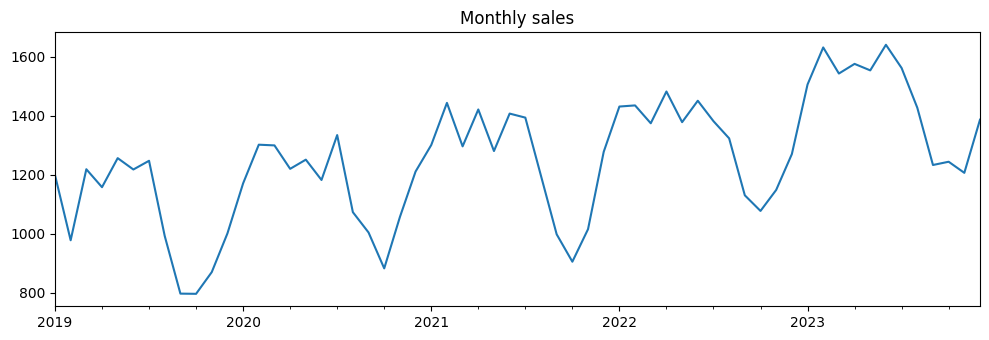

In [2]:
# 60 months from 2019-01
csv = DATA_DIR / "monthly_sales.csv"
if csv.exists():
    series = pd.read_csv(csv, parse_dates=["date"]).set_index("date")["sales"]
    source = "local csv"
else:
    n = 60
    idx = pd.date_range("2019-01-01", periods=n, freq="MS")
    t = np.arange(n)
    trend = 1000 + 8 * t
    season = 220 * np.sin(2 * np.pi * (t % 12) / 12) + 90 * np.cos(2 * np.pi * (t % 12) / 6)
    noise = RNG.normal(0, 60, n)
    series = pd.Series(trend + season + noise, index=idx, name="sales")
    source = "synthetic"

print(f"source: {source}  range: {series.index.min().date()} -> {series.index.max().date()}")
series.plot(figsize=(10, 3.5), title="Monthly sales"); plt.tight_layout(); plt.show()

In [3]:
# hold out the last 12 months as a test window
train, test = series.iloc[:-12], series.iloc[-12:]

# SARIMA(1,1,1)(1,1,1,12) is a reasonable starting point for monthly data with annual seasonality.
# I tried (0,1,1)(0,1,1,12) too, results were close.
model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False, enforce_invertibility=False)
res = model.fit(disp=False)
print(res.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4100      0.326     -1.258      0.208      -1.049       0.229
ma.L1         -0.8414      0.258     -3.265      0.001      -1.347      -0.336
ar.S.L12      -0.4191      0.300     -1.397      0.162      -1.007       0.169
ma.S.L12      -0.2591      0.625     -0.415      0.678      -1.484       0.966
sigma2      3630.8430   2090.084      1.737      0.082    -465.647    7727.333


In [4]:
forecast = res.get_forecast(steps=12)
fc_mean = forecast.predicted_mean
ci = forecast.conf_int(alpha=0.2)  # 80% interval, easier to read than 95%

mae = mean_absolute_error(test, fc_mean)
mape = (np.abs(test - fc_mean) / test).mean() * 100
print(f"holdout MAE: {mae:.1f}   MAPE: {mape:.2f}%")

holdout MAE: 57.6   MAPE: 3.95%


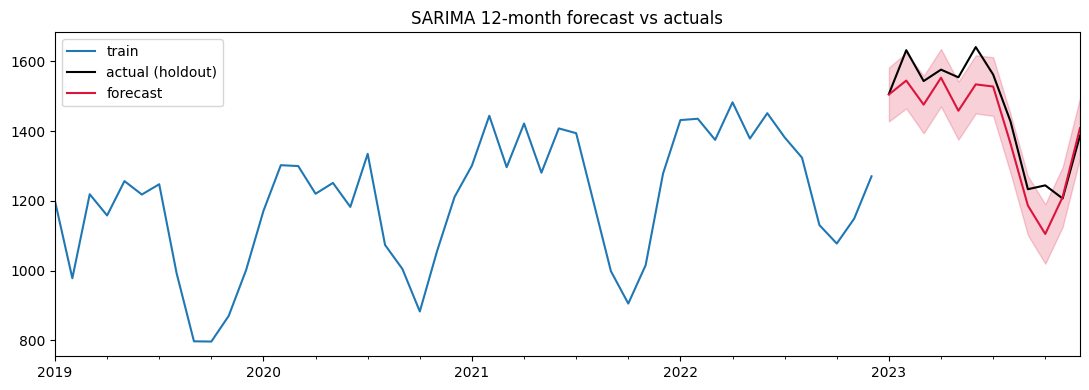

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
train.plot(ax=ax, label="train")
test.plot(ax=ax, label="actual (holdout)", color="black")
fc_mean.plot(ax=ax, label="forecast", color="crimson")
ax.fill_between(fc_mean.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, color="crimson")
ax.legend(); ax.set_title("SARIMA 12-month forecast vs actuals")
plt.tight_layout(); plt.show()

## What I learned

SARIMA is a lot of typing for what amounts to "learn the trend, learn the seasonal swing, project forward." The 80% confidence band is the most useful thing the model gives me — point forecasts get all the attention but anybody making a decision off this needs to know that the December estimate has an honest range of plus/minus a chunk.

Things I'd want to do before trusting this on real revenue data:
- Cross-validate with a rolling-origin scheme, not just one holdout. A single 12-month tail can be lucky.
- Check residual autocorrelation. If the residuals still have structure I'm leaving signal on the table.
- For a real business series, also try Prophet (it handles holidays cleanly) and a gradient-boosted model on lag features. Ensembling them often beats any one of them.